In [1]:
import pandas as pd

df_train = pd.read_json("train.json")
df_test = pd.read_json("test.json")

df_train.head()

,image_path,cartoon_class
0,images/train_0001.png,Pokemon
1,images/train_0002.png,Pokemon
2,images/train_0003.png,Snow White
3,images/train_0004.png,Tarzan
4,images/train_0005.png,Tarzan


In [2]:
df_train.cartoon_class.unique()

array(['Pokemon', 'Snow White', 'Tarzan', 'Winnie the Pooh'], dtype=object)

1024
1024


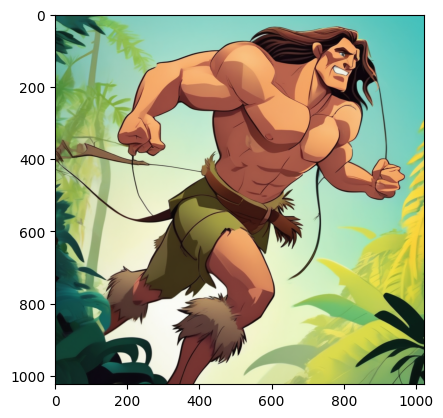

In [3]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open('images/train_0004.png') # se observa ca toate au size 1024x1024
print(img.size[0])
print(img.size[1])
plt.imshow(img)

In [4]:
from sklearn.preprocessing import LabelEncoder
enc = LabelEncoder()
df_train.cartoon_class = enc.fit_transform(df_train.cartoon_class)

df_train.head()

,image_path,cartoon_class
0,images/train_0001.png,0
1,images/train_0002.png,0
2,images/train_0003.png,1
3,images/train_0004.png,2
4,images/train_0005.png,2


In [25]:
import torch

epochs = 3
batch_size = 32
learning_rate= 0.0001

device = torch.device('cuda')
device

device(type='cuda')

In [26]:
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

train_transforms = T.Compose([
    T.Resize((512, 512)),
    T.ToTensor()
])

valid_transforms = T.Compose([
    T.Resize((512, 512)),
    T.ToTensor()
])

class MyDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        path = self.df.image_path.iloc[idx]
        img = Image.open(path)
        img = self.transform(img)
        label = torch.tensor(self.df.cartoon_class.iloc[idx], dtype=torch.int64)
        return img, label

from sklearn.model_selection import train_test_split
df_1, df_2 = train_test_split(df_train, test_size=0.1, random_state=42)

train_dataset = MyDataset(df_1, train_transforms)
train_loader = DataLoader(train_dataset, batch_size=batch_size)

valid_dataset = MyDataset(df_2, valid_transforms)
valid_loader = DataLoader(valid_dataset, batch_size=batch_size)

In [27]:
train_dataset[0][0][0][0][0]

tensor(0.2588)

In [28]:
import torch.nn as nn
import torchvision.models

model = torchvision.models.resnet18(weights='IMAGENET1K_V1')

model = model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
model

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [29]:
def train(model, criterion, train_loader, optimizer, epoch):
    model.train()
    total_loss = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(inputs), labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f'Epoch {epoch}')
    print(f'Training Loss {total_loss/len(train_loader)}')
def test(model, criterion, test_loader):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            loss = criterion(model(inputs), labels)
            total_loss += loss.item()
    print(f'Validation Loss {total_loss/len(test_loader)}')

In [30]:
for epoch in range(1, epochs+1):
    train(model, criterion, train_loader, optimizer, epoch)
    test(model, criterion, valid_loader)

Epoch 1
Training Loss 5.018860816955566
Validation Loss 2.186145782470703
Epoch 2
Training Loss 0.4567650593817234
Validation Loss 0.6091934442520142
Epoch 3
Training Loss 0.042453565479566656
Validation Loss 0.25578030943870544


In [31]:
final_transforms = T.Compose([
    T.Resize((512, 512)),
    T.ToTensor()
])

class FinalDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        path = self.df.image_path.iloc[idx]
        img = Image.open(path)
        img = self.transform(img)
        return img

final_dataset = FinalDataset(df_test, final_transforms)
final_loader = DataLoader(final_dataset, batch_size=batch_size)

In [32]:
model.eval()
preds = []

with torch.no_grad():
    for inputs in final_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        outputs = torch.argmax(outputs, dim=1).cpu().numpy()
        preds.extend(outputs)

preds[:10]

[0, 0, 0, 2, 2, 3, 3, 3, 2, 3]

In [33]:
preds = enc.inverse_transform(preds)
preds[:10]

array(['Pokemon', 'Pokemon', 'Pokemon', 'Tarzan', 'Tarzan',
       'Winnie the Pooh', 'Winnie the Pooh', 'Winnie the Pooh', 'Tarzan',
       'Winnie the Pooh'], dtype=object)

In [34]:
submission = pd.DataFrame({
    "image_path": df_test.image_path,
    "cartoon_class": preds
})

submission

,image_path,cartoon_class
0,images/test_0001.png,Pokemon
1,images/test_0002.png,Pokemon
2,images/test_0003.png,Pokemon
3,images/test_0004.png,Tarzan
4,images/test_0005.png,Tarzan
...,...,...
95,images/test_0096.png,Tarzan
96,images/test_0097.png,Winnie the Pooh
97,images/test_0098.png,Winnie the Pooh
98,images/test_0099.png,Pokemon


In [35]:
submission.to_csv("submission.csv", index=False)